# Artificial Intelligence

## Home Battery Scheduling with Deep Reinforcement Learning

Md. Jalil Piran · Sejong University · piran@sejong.ac.kr

**Project question.** Can a home battery controller learn when to buy cheap electricity and use it later, even when the daily price schedule changes?

In the previous notebook, tabular Q-learning learned one six-slot tariff. The grid-only bill was 23 units, and the learned battery schedule reduced it to 10 units. Here, the battery works the same way. The controller uses a **Deep Q-Network (DQN)** so it can estimate action values for price schedules it has never encountered.

By the end, you will be able to:

- Describe the observation, actions, and reward in a battery scheduling problem.
- Explain how a neural network, experience replay, and a target network extend Q-learning.
- Evaluate a learned controller against grid-only use, a simple rule, and the cheapest feasible schedule.

**Before you start.** You should know basic Python and have seen tabular Q-learning. Run the cells in order. If packages are missing, run `%pip install numpy pandas matplotlib scikit-learn` in a notebook cell and restart the kernel if prompted. The project uses synthetic tariffs and runs on a CPU.

## 1. Set up the six-slot day

The home needs 1 kWh in each slot. The lossless battery starts empty and can store up to 2 kWh. The full price schedule is published at the beginning of the day. The battery cannot sell electricity back to the grid, and any charge left after slot 6 has zero value.

| Action | Change in stored energy | Electricity bought from the grid |
|---|---:|---:|
| Discharge | −1 kWh | 0 kWh |
| Idle | 0 kWh | 1 kWh |
| Charge | +1 kWh | 2 kWh |

If slot 1 costs 1 unit/kWh and the battery charges, the grid supplies 1 kWh for the home and 1 kWh for the battery. The slot costs 2 units, so the reward is −2. We use $gamma=1$ because all six costs count equally toward the bill and the episode ends after slot 6.

In [1]:
from collections import deque
from copy import deepcopy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.neural_network import MLPRegressor

SEED = 42
ORIGINAL_DAY = np.array([1, 2, 6, 5, 2, 7])
N_SLOTS = len(ORIGINAL_DAY)
CAPACITY = 2
DEMAND = 1
GAMMA = 1.0

DISCHARGE, IDLE, CHARGE = range(3)
ACTION_NAMES = ["Discharge", "Idle", "Charge"]
CHARGE_CHANGES = np.array([-1, 0, 1])
N_ACTIONS = len(ACTION_NAMES)


def action_mask(charge):
    # Works with a single charge or a batch of charges.
    next_charge = np.asarray(charge)[..., None] + CHARGE_CHANGES
    return (next_charge >= 0) & (next_charge <= CAPACITY)


def step(prices, slot, charge, action):
    if not action_mask(charge)[action]:
        raise ValueError("Action exceeds the battery limits.")

    change = int(CHARGE_CHANGES[action])
    grid_energy = DEMAND + change
    cost = int(prices[slot]) * grid_energy
    done = slot == N_SLOTS - 1
    return charge + change, -cost, done


assert action_mask(0).tolist() == [False, True, True]
assert action_mask(CAPACITY).tolist() == [True, True, False]
assert step(ORIGINAL_DAY, 0, 0, CHARGE) == (1, -2, False)
assert step(ORIGINAL_DAY, 5, 1, DISCHARGE) == (0, 0, True)

## 2. Create training and test days

Some days have a large price increase near the middle of the day. Others peak earlier or later. We create several versions of each tariff by varying every slot by up to 1 unit/kWh. Each daily profile appears only once in the dataset.

The DQN learns from 180 tariffs. We reserve 36 unseen tariffs for the final comparison and keep the original tariff as a separate reference day. The plot shows the four underlying tariff shapes. These synthetic days let us test generalization to new prices within the same family of tariffs.

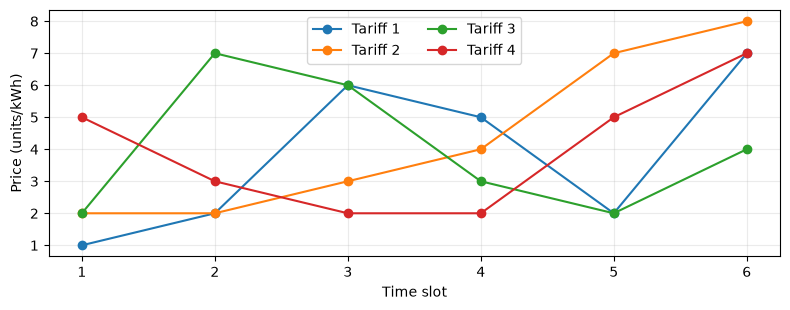

In [2]:
base_tariffs = np.array([
    [1, 2, 6, 5, 2, 7],
    [2, 2, 3, 4, 7, 8],
    [2, 7, 6, 3, 2, 4],
    [5, 3, 2, 2, 5, 7],
])

data_rng = np.random.default_rng(SEED)
profiles = set()
while len(profiles) < 216:
    base = base_tariffs[data_rng.integers(len(base_tariffs))]
    prices = np.maximum(1, base + data_rng.integers(-1, 2, size=N_SLOTS))
    if not np.array_equal(prices, ORIGINAL_DAY):
        profiles.add(tuple(prices.tolist()))

profiles = data_rng.permutation(np.array(sorted(profiles)))
train_days = profiles[:180]
test_days = profiles[180:]
slots = np.arange(1, N_SLOTS + 1)

fig, ax = plt.subplots(figsize=(8, 3.2))
for index, prices in enumerate(base_tariffs, start=1):
    ax.plot(slots, prices, marker="o", label=f"Tariff {index}")
ax.set(xlabel="Time slot", ylabel="Price (units/kWh)", xticks=slots)
ax.legend(ncol=2)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 3. Replace the Q-table with a neural network

In tabular Q-learning, the state was just the slot and the charge. Here the agent also needs the day's tariff. A separate Q-table row for every distinct price schedule would leave the agent with no learned values on a new day. A neural network shares what it learns across similar inputs.

The network takes 13 inputs: six binary indicators for the current slot, the fraction of the battery that is full, and the six published prices divided by 10. It has two hidden layers with 32 neurons each and produces three estimates, $Q(s,mathrm{discharge})$, $Q(s,mathrm{idle})$, and $Q(s,mathrm{charge})$. Higher Q-values mean lower predicted costs.

The **action mask** limits exploration, greedy decisions, and the learning target to actions the battery can actually take.

In [3]:
slot_indicators = np.eye(N_SLOTS)


def observation(prices, slot, charge):
    return np.concatenate([
        slot_indicators[slot],
        [charge / CAPACITY],
        prices / 10.0,
    ])


def best_action(q_values, charge):
    return int(np.argmax(np.where(action_mask(charge), q_values, -np.inf)))


def choose_action(network, state, charge, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.choice(np.flatnonzero(action_mask(charge))))

    q_values = network.predict(state[None, :])[0]
    return best_action(q_values, charge)


example = observation(ORIGINAL_DAY, slot=0, charge=0)
print("Slot indicators:", example[:N_SLOTS].astype(int))
print("Battery fraction:", example[N_SLOTS])
print("Scaled tariff:", example[N_SLOTS + 1:])

Slot indicators: [1 0 0 0 0 0]
Battery fraction: 0.0
Scaled tariff: [0.1 0.2 0.6 0.5 0.2 0.7]


## 4. Learn from replayed experience

The **replay buffer** stores past transitions $(s,a,r,s',mathrm{done})$ and the next battery charge for action masking. Each update draws a random batch from the buffer, so the network can learn from different days and actions in the same update.

The **online network** chooses actions and learns from each batch. A temporary copy called the **target network** supplies the next-state values. We refresh the target network periodically so that the target changes less often.

$$
y =
egin{cases}
r, & 	ext{if the day ends},\[2pt]
r + gamma max_{a',	ext{feasible}} Q_{mathrm{target}}(s',a'), & 	ext{otherwise}.
end{cases}
$$

For each sampled transition, we take the three predictions from the online network and replace the prediction for the action actually taken with $y$. The other two predictions are copied as their own training targets, giving zero error on those outputs at the start of the update. One call to `partial_fit` takes an optimizer step on this batch using squared error. The shared layers allow this step to change Q-values on other states, too.

In [4]:
BATCH_SIZE = 64


def learn_from_replay(online, target, replay, rng):
    indices = rng.choice(len(replay), size=BATCH_SIZE, replace=False)
    batch = [replay[index] for index in indices]
    states, actions, rewards, next_states, next_charges, done = zip(*batch)

    states = np.stack(states)
    next_states = np.stack(next_states)
    done = np.asarray(done, dtype=bool)

    targets = np.asarray(rewards, dtype=float)
    # Terminal transitions keep just their immediate reward.
    continuing = ~done
    if continuing.any():
        next_q = target.predict(next_states[continuing])
        feasible = action_mask(np.asarray(next_charges)[continuing])
        best_next_q = np.where(feasible, next_q, -np.inf).max(axis=1)
        targets[continuing] += GAMMA * best_next_q

    training_targets = online.predict(states)
    training_targets[np.arange(BATCH_SIZE), actions] = targets
    online.partial_fit(states, training_targets)

## 5. Train the DQN on simulated days

Each episode starts with an empty battery and a randomly selected training tariff. At first, the agent explores by sampling feasible actions. As $
arepsilon$ decreases, the agent follows its own Q-value estimates more often.

The network makes one update every two interactions once the replay buffer has at least 64 transitions. The target network is refreshed every 100 updates. The cost plot averages the last 100 training days. Since the agent sometimes explores during training, we will evaluate the final policy separately with greedy actions.

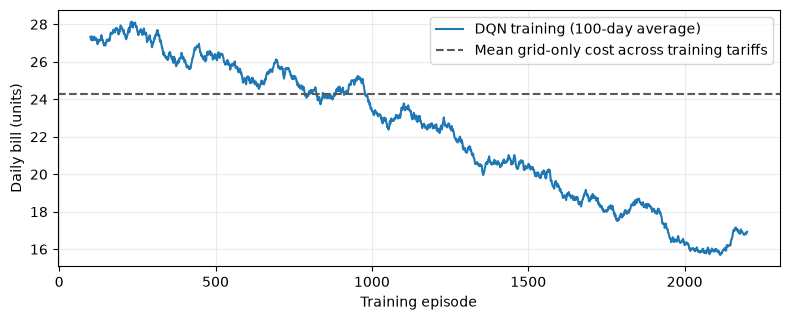

In [5]:
def train_dqn(days, episodes=2200, seed=SEED):
    rng = np.random.default_rng(seed)
    online = MLPRegressor(
        hidden_layer_sizes=(32, 32),
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        alpha=0.0,
        batch_size=BATCH_SIZE,
        shuffle=False,
        random_state=seed,
    )
    # A dummy batch creates the network weights before the first prediction.
    # All scheduling updates below use real simulator transitions.
    initial_inputs = np.zeros((BATCH_SIZE, 2 * N_SLOTS + 1))
    initial_targets = np.zeros((BATCH_SIZE, N_ACTIONS))
    online.partial_fit(initial_inputs, initial_targets)
    target = deepcopy(online)
    replay = deque(maxlen=4000)
    daily_costs = []
    steps = updates = 0

    exploration = np.linspace(1.0, 0.05, episodes)
    for epsilon in exploration:
        prices = days[rng.integers(len(days))]
        charge = 0
        state = observation(prices, 0, charge)
        daily_cost = 0

        for slot in range(N_SLOTS):
            action = choose_action(online, state, charge, epsilon, rng)
            next_charge, reward, done = step(prices, slot, charge, action)
            # A terminal transition never uses the next observation for learning.
            next_state = (
                np.zeros_like(state) if done
                else observation(prices, slot + 1, next_charge)
            )
            replay.append((state, action, reward, next_state, next_charge, done))
            state, charge = next_state, next_charge
            daily_cost -= reward
            steps += 1

            if len(replay) >= BATCH_SIZE and steps % 2 == 0:
                learn_from_replay(online, target, replay, rng)
                updates += 1
                if updates % 100 == 0:
                    target = deepcopy(online)

        daily_costs.append(daily_cost)

    return online, np.asarray(daily_costs)


network, daily_costs = train_dqn(train_days)
rolling_cost = pd.Series(daily_costs).rolling(100).mean()

fig, ax = plt.subplots(figsize=(8, 3.3))
ax.plot(np.arange(1, len(daily_costs) + 1), rolling_cost,
        label="DQN training (100-day average)")
ax.axhline(train_days.sum(axis=1).mean() * DEMAND, color="0.35",
           linestyle="--", label="Mean grid-only cost across training tariffs")
ax.set(xlabel="Training episode", ylabel="Daily bill (units)")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Evaluate against three benchmarks

- **Grid only** buys all the electricity directly from the grid.
- **Price rule** charges at or below the day's lower price quartile and discharges at or above the upper quartile, subject to battery limits. It otherwise stays idle.
- **Exact optimum** works backward from the end of the day. At each slot and starting charge, it tries each feasible action and adds its immediate cost to the cheapest remaining cost. This is called **dynamic programming**. It uses the published tariff and simulator rules to give a reference value for each day.

The DQN selects the best feasible action according to its learned estimates. The **optimality gap** is the DQN bill minus the exact optimum. A gap of zero means it matched the best achievable bill for that day.

In [6]:
def dqn_policy(prices, slot, charge):
    state = observation(prices, slot, charge)
    return best_action(network.predict(state[None, :])[0], charge)


def price_rule(prices, slot, charge):
    low, high = np.quantile(prices, [0.25, 0.75])
    if prices[slot] >= high and charge > 0:
        return DISCHARGE
    if prices[slot] <= low and charge < CAPACITY:
        return CHARGE
    return IDLE


def simulate_day(prices, policy):
    charge = 0
    schedule = []
    for slot, price in enumerate(prices):
        action = policy(prices, slot, charge)
        next_charge, reward, _ = step(prices, slot, charge, action)
        schedule.append({
            "Slot": slot + 1,
            "Price (units/kWh)": price,
            "Battery before (kWh)": charge,
            "Action": ACTION_NAMES[action],
            "Grid purchase (kWh)": DEMAND + CHARGE_CHANGES[action],
            "Battery after (kWh)": next_charge,
            "Cost (units)": -reward,
        })
        charge = next_charge
    return pd.DataFrame(schedule).set_index("Slot")


def optimal_cost(prices):
    # Rows are slots; columns are possible starting charges.
    # The final row is zero because nothing is paid after the day ends.
    remaining = np.zeros((N_SLOTS + 1, CAPACITY + 1), dtype=int)
    for slot in range(N_SLOTS - 1, -1, -1):
        for charge in range(CAPACITY + 1):
            possible_costs = []
            for action in np.flatnonzero(action_mask(charge)):
                next_charge, reward, _ = step(prices, slot, charge, action)
                possible_costs.append(-reward + remaining[slot + 1, next_charge])
            remaining[slot, charge] = min(possible_costs)
    return int(remaining[0, 0])


if CAPACITY == 2:
    assert optimal_cost(ORIGINAL_DAY) == 10

## 7. Inspect the original six-slot day

Read the DQN schedule one slot at a time. Compare the prices when it buys extra electricity with the prices when it supplies the home from the battery. If the gap is nonzero, identify one feasible change that would lower the bill.

In [7]:
reference_schedule = simulate_day(ORIGINAL_DAY, dqn_policy)
display(reference_schedule)

reference_bill = reference_schedule["Cost (units)"].sum()
reference_optimum = optimal_cost(ORIGINAL_DAY)
print(f"Grid-only bill: {DEMAND * ORIGINAL_DAY.sum()} units")
print(f"DQN bill: {reference_bill} units")
print(f"Exact optimum: {reference_optimum} units")
print(f"DQN optimality gap: {reference_bill - reference_optimum} units")

,Price (units/kWh),Battery before (kWh),Action,Grid purchase (kWh),Battery after (kWh),Cost (units)
Slot,,,,,,
1,1,0,Charge,2,1,2
2,2,1,Charge,2,2,4
3,6,2,Discharge,0,1,0
4,5,1,Discharge,0,0,0
5,2,0,Charge,2,1,4
6,7,1,Discharge,0,0,0


Grid-only bill: 23 units
DQN bill: 10 units
Exact optimum: 10 units
DQN optimality gap: 0 units


## 8. Test on unseen tariffs

Every controller is evaluated on the same 36 days. The table reports the mean bill and mean gap above the exact optimum. The histogram counts how often the DQN matches the exact optimum and how large its errors are on the other days. Inspect the largest-gap day to see where the agent's schedule can improve.

,Mean bill (units),Mean gap (units)
Grid only,24.72,9.11
Price rule,18.19,2.58
DQN,15.75,0.14
Exact optimum,15.61,0.00


DQN savings against grid only: 36.3% across the test days
DQN matched the optimum on 32 of 36 days.


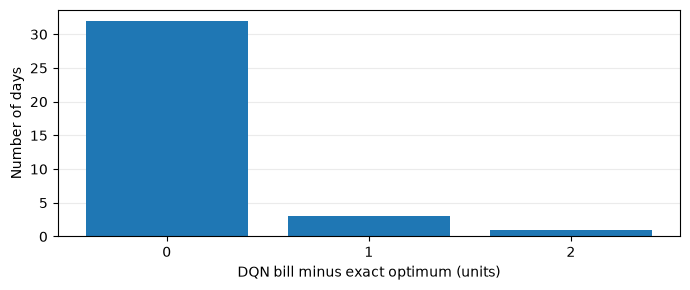

Largest-gap day: day 7, gap 2 units


,Price (units/kWh),Battery before (kWh),Action,Grid purchase (kWh),Battery after (kWh),Cost (units)
Slot,,,,,,
1,2,0,Charge,2,1,4
2,7,1,Idle,1,1,7
3,5,1,Discharge,0,0,0
4,2,0,Idle,1,0,2
5,2,0,Charge,2,1,4
6,5,1,Discharge,0,0,0


In [8]:
records = []
for prices in test_days:
    records.append({
        "Grid only": int(DEMAND * prices.sum()),
        "Price rule": simulate_day(prices, price_rule)["Cost (units)"].sum(),
        "DQN": simulate_day(prices, dqn_policy)["Cost (units)"].sum(),
        "Exact optimum": optimal_cost(prices),
    })

bills = pd.DataFrame(records, index=pd.RangeIndex(1, len(test_days) + 1, name="Day"))
gaps = bills.sub(bills["Exact optimum"], axis=0)
assert (gaps >= 0).all().all()

summary = pd.DataFrame({
    "Mean bill (units)": bills.mean(),
    "Mean gap (units)": gaps.mean(),
})
display(summary.round(2))

dqn_gaps = gaps["DQN"]
savings = 100 * (bills["Grid only"].sum() - bills["DQN"].sum()) / bills["Grid only"].sum()
print(f"DQN savings against grid only: {savings:.1f}% across the test days")
print(f"DQN matched the optimum on {(dqn_gaps == 0).sum()} of {len(test_days)} days.")

gap_counts = dqn_gaps.value_counts().reindex(
    range(int(dqn_gaps.max()) + 1), fill_value=0
).sort_index()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(gap_counts.index, gap_counts, color="tab:blue")
ax.set(xlabel="DQN bill minus exact optimum (units)", ylabel="Number of days",
       xticks=gap_counts.index)
ax.set_axisbelow(True)
ax.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.show()

worst_day = int(dqn_gaps.idxmax())
print(f"Largest-gap day: day {worst_day}, gap {dqn_gaps.loc[worst_day]} units")
display(simulate_day(test_days[worst_day - 1], dqn_policy))